## Lab #2

Katherine Merrill

10-14-2026

Phys 434 AC

# Problem 1
### A) Show how the probability distribution of the background changes as you integrate (sum) for more days

For the pdf of a Poisson distribution, $P(k)=e^{-X}X^k/k!$, $\lambda$ = the average cosmic ray background X=2.3, and for the expected signal of source and background, $\lambda =X+Y=2.3+4=6.3 $ . 

The integral will be another Poisson distribution since the sum is equal to the convolutons of each of the probability distributions:
The convolved probabilities of the count from day 1 to the count from day 5 give the distribution for the total sum over 5 days. I plotted each of the convolved distribution curves below:

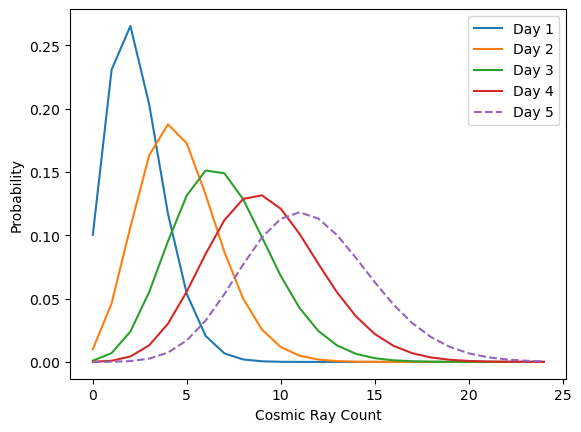

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

X = 2.3  # daily average

k = np.arange(0, 25)
day1 = stats.poisson.pmf(k, X)

day2 = np.convolve(day1, day1)[:25]
day3 = np.convolve(day2, day1)[:25]
day4 = np.convolve(day3, day1)[:25]
day5 = np.convolve(day4, day1)[:25]

plt.plot(k, day1, label='Day 1')
plt.plot(k, day2, label='Day 2')
plt.plot(k, day3, label='Day 3')
plt.plot(k, day4, label='Day 4')
plt.plot(k, day5, label='Day 5', linestyle='--')

plt.xlabel('Cosmic Ray Count')
plt.ylabel('Probability')
plt.legend()
plt.show()


# Part B:

In [44]:
# Theoretical 5-day Poisson PMF evaluated over the same 25 points
theoretical_day5 = stats.poisson.pmf(k, 5 * X)

# Calculate the maximum absolute difference
max_diff = np.max(np.abs(d5 - theoretical_day5))

print(max_diff)

2.0816681711721685e-16


The summed probability distribution (theoretical_day5) only has a difference of 2.0816681711721685e-16 with the convolved version (day5_dist). This is a floating-point error and basically 0. So it still represents the same Poisson distribution. 
This makes sense mathematically because the individual variables $X_i$ that represent the cosmic ray background count for a single day from i=1 to n=5  and their associated rates $\lambda_i$ are all the same (2.3 events per day), their sum $\Sigma x_0$ is the total cosmic ray count accumulated over 5 days, and the new rate $\Sigma \lambda_i$ becomes lambda total =11.5. 

I think the *Sums of Poisson-Distributed Random Variables* section of the Poisson Distribution Wikipedia page put it a bit more eloquently, where the summing operation is the same use the convolving operation:
"*If $X_i \sim \operatorname{Pois}(\lambda_i)$ for $i=1, \dots, n$ are independent, then:*

$$\sum_{i=1}^{n}X_i \sim \operatorname{Pois}\left(\sum_{i=1}^{n}\lambda_i\right)$$

*A converse is $\textbf{Raikov's theorem}$, which states that if the sum of 
two independent random variables is Poisson-distributed, then so is 
each of those two individual independent random variables.*"

.
[Wikipedia Page](https://en.wikipedia.org/wiki/Poisson_distribution) 

## C) Show how the probability distribution evolves as you average days. Calculate for many different ranges of days, and explore the shape of the distribution as the number of days becomes larger. Discuss this in relation to both B) and the central limit theoem.

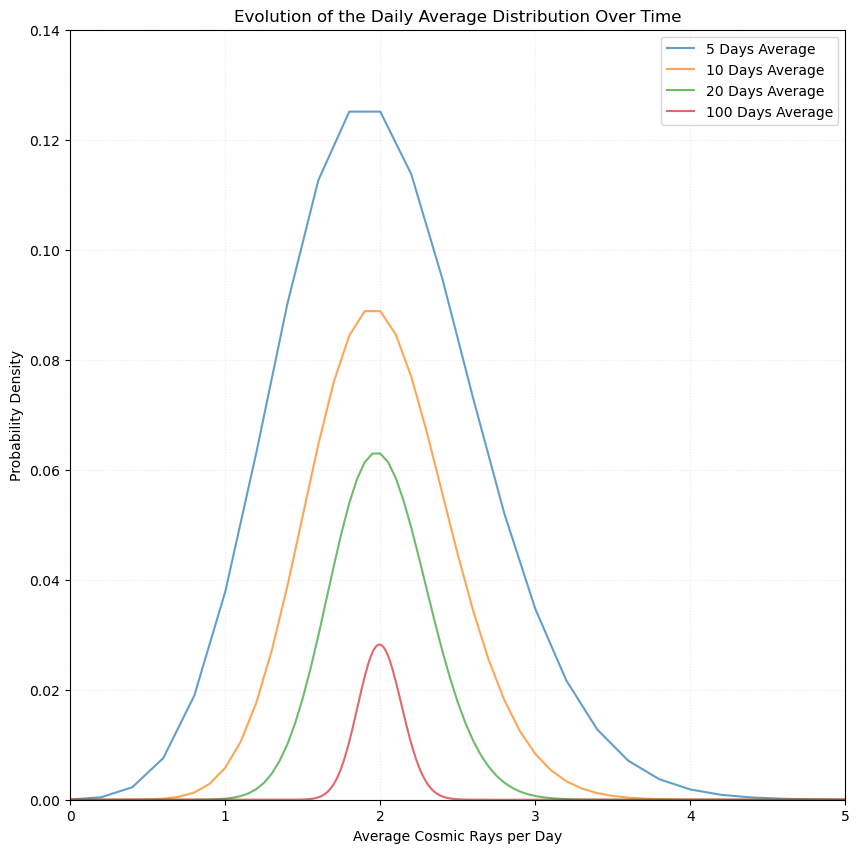

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

X = 2.3

days_to_check = [5, 10, 20, 100]

plt.figure(figsize=(10, 10))

for N in days_to_check:
    k_sum = np.arange(0, int(N * X * 3) + 10)
    p_sum = stats.poisson.pmf(k_sum, N * X)
    
    k_avg = k_sum / N
    
    plt.plot(k_avg, p_sum, label=f'{N} Days Average', alpha=0.7)

plt.title('Evolution of the Daily Average Distribution Over Time')
plt.xlabel('Average Cosmic Rays per Day')
plt.ylabel('Probability Density')
plt.xlim(0, 5)
plt.ylim(0,.14)
plt.legend()
plt.grid(True, linestyle=':', alpha=.25)
plt.show()


As I average over N days, the probability distribution begins to look more like a Gaussian distribution as I increase the number of days. This relates to part B because the discrete probabilities of getting a certain average are the same as those of that corresponding sum, so they will both be determined by the same Poisson distribution. 